In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import seaborn as sns
from reg_helper import *
from plots import *
import random

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [3]:
%load_ext autoreload
%autoreload 2
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shivam2503/diamonds")

print("Path to dataset files:", path)

/home/bibeda/DSpractice/Classic_ML_reg/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /home/bibeda/.cache/kagglehub/datasets/shivam2503/diamonds/versions/1


In [5]:
!mv {path}/* .

mv: cannot stat '/home/bibeda/.cache/kagglehub/datasets/shivam2503/diamonds/versions/1/*': No such file or directory


In [6]:
data = pd.read_csv('diamonds.csv')
data.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [7]:
print(data.shape)
data.info()

(53940, 11)
<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  str    
 3   color       53940 non-null  str    
 4   clarity     53940 non-null  str    
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), str(3)
memory usage: 4.5 MB


In [8]:
data = data.drop(columns=['Unnamed: 0']) # Дропнем ненужный столбец
data.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [9]:
data.isna().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [10]:
data.duplicated().sum() 

np.int64(146)

In [11]:
data.drop_duplicates(inplace=True) #удалим дубликаты

In [12]:
data.describe() 

,carat,depth,table,price,x,y,z
count,53794.00000,53794.000000,53794.000000,53794.000000,53794.000000,53794.000000,53794.000000
mean,0.79778,61.748080,57.458109,3933.065082,5.731214,5.734653,3.538714
std,0.47339,1.429909,2.233679,3988.114460,1.120695,1.141209,0.705037
min,0.20000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.40000,61.000000,56.000000,951.000000,4.710000,4.720000,2.910000
50%,0.70000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.04000,62.500000,59.000000,5326.750000,6.540000,6.540000,4.030000
max,5.01000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


# Корректность данных

| Признак | Описание | Диапазон значений |
|---------|----------|-------------------|
| **price** | Цена бриллианта в долларах США | $326–$18 823 |
| **carat** | Вес бриллианта в каратах | 0.2–5.01 |
| **cut** | Качество огранки бриллианта | Fair (удовлетворительное), Good (хорошее), Very Good (очень хорошее), Premium (премиальное), Ideal (идеальное) |
| **color** | Цвет бриллианта: от J (худший) до D (лучший) | J, I, H, G, F, E, D |
| **clarity** | Чистота бриллианта (степень отсутствия внутренних включений и внешних дефектов) | I1 (худшая), SI2, SI1, VS2, VS1, VVS2, VVS1, IF (лучшая) |
| **x** | Длина бриллианта в миллиметрах | 0–10.74 |
| **y** | Ширина бриллианта в миллиметрах | 0–58.9 |
| **z** | Высота бриллианта в миллиметрах | 0–31.8 |
| **depth** | Относительная глубина бриллианта в процентах: `2 * z / (x + y) * 100` | 43–79 |
| **table** | Ширина верхней плоской грани бриллианта относительно его максимальной ширины (в процентах) | 43–95 |


In [13]:
def find_out_of_range_values(df, column, min_val, max_val):
    return len(df[
        ~df[column].between(min_val, max_val)
    ])

In [14]:
print(find_out_of_range_values(data, 'price', 326, 18823))
print(find_out_of_range_values(data, 'carat', 0.2, 5.01))
print(find_out_of_range_values(data, 'x', 1, 10.74))
print(find_out_of_range_values(data, 'y', 1, 58.9))
print(find_out_of_range_values(data, 'z', 1, 31.8))
print(find_out_of_range_values(data, 'depth', 43, 79))
print(find_out_of_range_values(data, 'table', 43, 95))

0
0
7
6
19
0
0


Подозрительно видеть, что бывают камни с размерами = 0 мм. Это точно аномалия. Рассматрим эти объекты более подробно.

In [15]:
data[data['x'] < 1]

,carat,cut,color,clarity,depth,table,price,x,y,z
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.0,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.0,0.00,0.0
15951,1.14,Fair,G,VS1,57.5,67.0,6381,0.0,0.00,0.0
24520,1.56,Ideal,G,VS2,62.2,54.0,12800,0.0,0.00,0.0
26243,1.20,Premium,D,VVS1,62.1,59.0,15686,0.0,0.00,0.0
27429,2.25,Premium,H,SI2,62.8,59.0,18034,0.0,0.00,0.0
49556,0.71,Good,F,SI2,64.1,60.0,2130,0.0,0.00,0.0


In [16]:
data[data['y'] < 1]

,carat,cut,color,clarity,depth,table,price,x,y,z
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.0,0.0,0.0
15951,1.14,Fair,G,VS1,57.5,67.0,6381,0.0,0.0,0.0
24520,1.56,Ideal,G,VS2,62.2,54.0,12800,0.0,0.0,0.0
26243,1.20,Premium,D,VVS1,62.1,59.0,15686,0.0,0.0,0.0
27429,2.25,Premium,H,SI2,62.8,59.0,18034,0.0,0.0,0.0
49556,0.71,Good,F,SI2,64.1,60.0,2130,0.0,0.0,0.0


In [17]:
data[data['z'] < 1]

,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.00,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
13601,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0
15951,1.14,Fair,G,VS1,57.5,67.0,6381,0.00,0.00,0.0
24394,2.18,Premium,H,SI2,59.4,61.0,12631,8.49,8.45,0.0


Есть вариант восстановить эти значения. Если в данных присутствует хотя бы две величины (x, y) и depth, то можно воспользоваться формулой depth = `2 * z / (x + y) * 100`. Однако таких аномальных строк мало относительно всего размера датасета, поэтому их можно спокойно удалить.

In [18]:
data = data[(data[['x', 'y', 'z']] != 0).all(axis=1)].copy()
data.shape

(53775, 10)

Также проверим величину depth, раз уж нам дали формулу её подсчёта

In [19]:
data['depth_counted'] = data['z'] * 2 / (data['x'] + data['y']) * 100
data['depth_diff'] = abs(data['depth'] - data['depth_counted'])
data.sort_values('depth_diff', ascending=False)

,carat,cut,color,clarity,depth,table,price,x,y,z,depth_counted,depth_diff
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80,619.279455,557.479455
14635,1.07,Ideal,F,SI1,60.6,57.0,5909,6.62,6.67,1.07,16.102333,44.497667
20694,1.53,Ideal,I,SI1,61.9,54.0,8971,7.43,7.50,1.53,20.495646,41.404354
21654,1.41,Ideal,H,VS1,60.7,56.0,9752,7.31,7.22,1.41,19.408121,41.291879
49905,0.50,Very Good,G,VVS1,63.7,58.0,2180,5.01,5.04,5.06,100.696517,36.996517
...,...,...,...,...,...,...,...,...,...,...,...,...
41715,0.47,Good,F,VS1,60.0,60.1,1243,5.04,5.06,3.03,60.000000,0.000000
41742,0.50,Premium,D,SI2,62.6,58.0,1243,5.04,4.96,3.13,62.600000,0.000000
41787,0.39,Ideal,E,IF,62.5,57.0,1248,4.70,4.74,2.95,62.500000,0.000000
46462,0.71,Good,I,SI1,60.0,64.0,1774,5.79,5.71,3.45,60.000000,0.000000


In [20]:
data[data['depth_diff'] > 1]

,carat,cut,color,clarity,depth,table,price,x,y,z,depth_counted,depth_diff
2274,1.22,Premium,J,SI2,62.6,59.0,3156,6.79,4.24,3.76,68.177697,5.577697
2349,0.70,Ideal,G,VS2,62.7,54.0,3172,5.65,5.70,3.65,64.317181,1.617181
2941,1.00,Very Good,J,SI2,62.8,63.0,3293,6.26,6.19,3.19,51.244980,11.555020
3511,0.70,Premium,E,IF,62.9,59.0,3403,5.66,5.59,3.40,60.444444,2.455556
4124,1.01,Fair,F,SI2,64.6,59.0,3540,6.19,6.25,4.20,67.524116,2.924116
...,...,...,...,...,...,...,...,...,...,...,...,...
52260,0.78,Premium,H,SI1,60.0,60.0,2489,5.93,5.92,3.62,61.097046,1.097046
52359,0.75,Premium,F,SI2,62.2,58.0,2501,5.87,5.80,3.57,61.182519,1.017481
53004,0.70,Premium,F,SI1,60.0,60.0,2596,5.62,5.55,3.60,64.458371,4.458371
53005,0.70,Premium,D,SI2,60.0,60.0,2596,5.72,5.56,3.50,62.056738,2.056738


Пусть допустимой погрешностью будет 1% и меньше, тогда остальные данные имеют ошибку. Всего это 80 строчек, 0,15% от исходного датасета, значит можно удалить.

In [21]:
index_to_drop = data[data['depth_diff'] > 1].index
data = data.drop(index=index_to_drop)

In [22]:
data['cut'].value_counts()

cut
Ideal        21468
Premium      13695
Very Good    12063
Good          4887
Fair          1582
Name: count, dtype: int64

In [23]:
data['color'].value_counts()

color
G    11234
E     9761
F     9506
H     8245
D     6750
I     5402
J     2797
Name: count, dtype: int64

In [24]:
data['clarity'].value_counts()

clarity
SI1     13007
VS2     12213
SI2      9119
VS1      8142
VVS2     5053
VVS1     3642
IF       1783
I1        736
Name: count, dtype: int64

Теперь данные без аномалий и соответствуют описанию!

# Рассмотрение данных

## Графики для одного признака

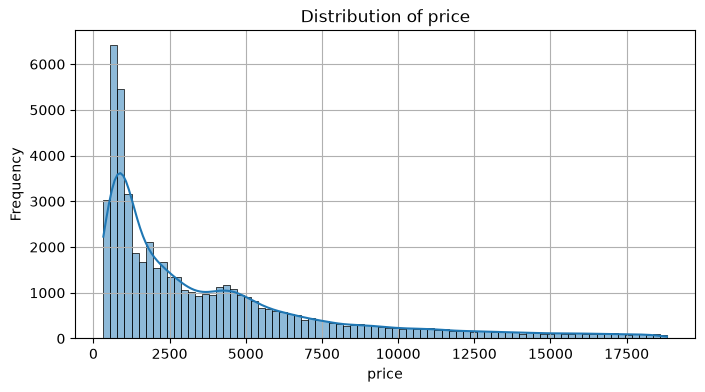

In [25]:
plot_hist_numeric(data, 'price')

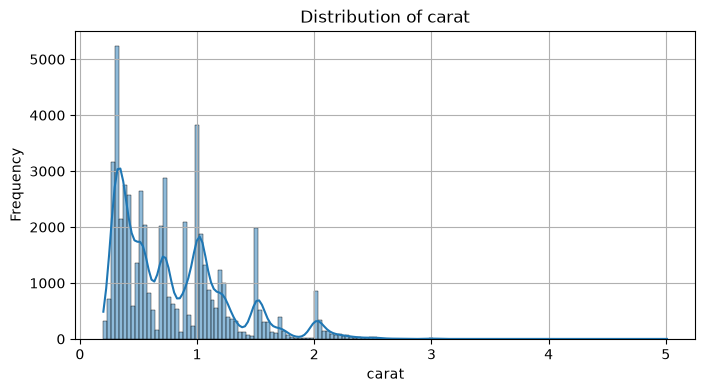

In [26]:
plot_hist_numeric(data, 'carat')

Распределение каратов мультимодальное. Возможно связано с тем, что ювелирам выгоднее округлять каратность камня до целых значений, поэтому на таких значениях как [1.0, 1.5, 2.0] больше значений, чем в промежутках.

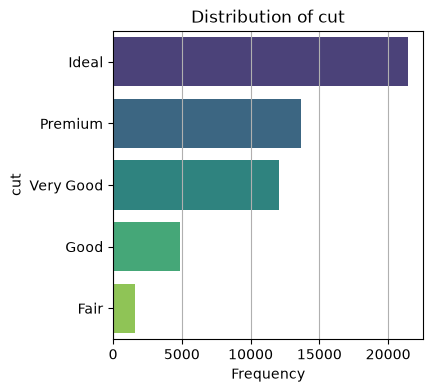

In [27]:
plot_hist_categorical(data, 'cut')

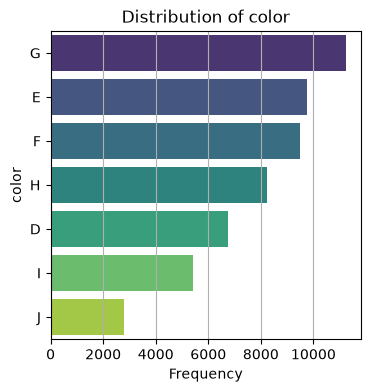

In [28]:
plot_hist_categorical(data, 'color')

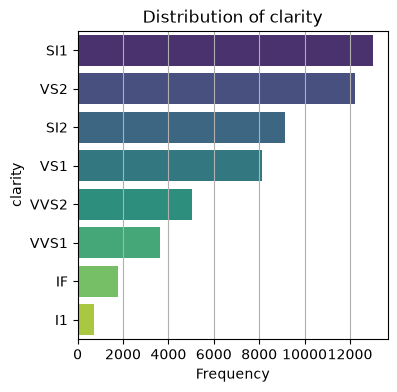

In [29]:
plot_hist_categorical(data, 'clarity')

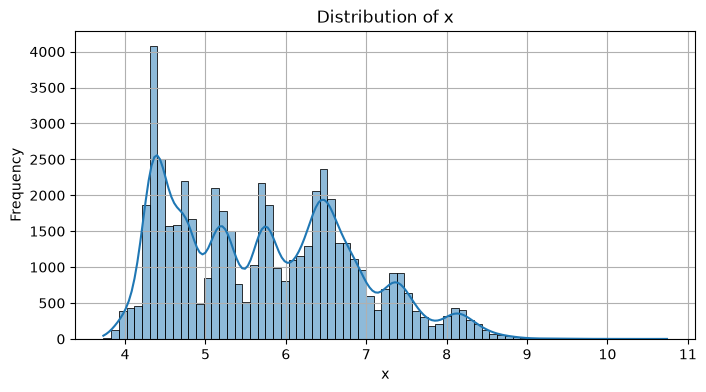

In [30]:
plot_hist_numeric(data, 'x')

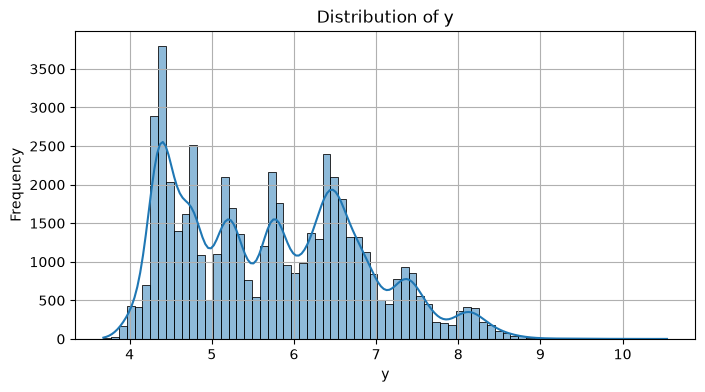

In [31]:
plot_hist_numeric(data, 'y')

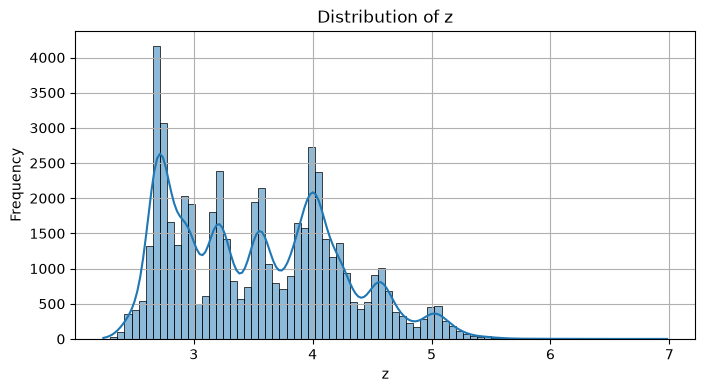

In [32]:
plot_hist_numeric(data, 'z')

Как и у признака "карат", можно заметить, что распределения размеров мультимодальные. Вес (карат) зависит от размеров камня. Эту гипотезу подтверждают следующие 3 графика:

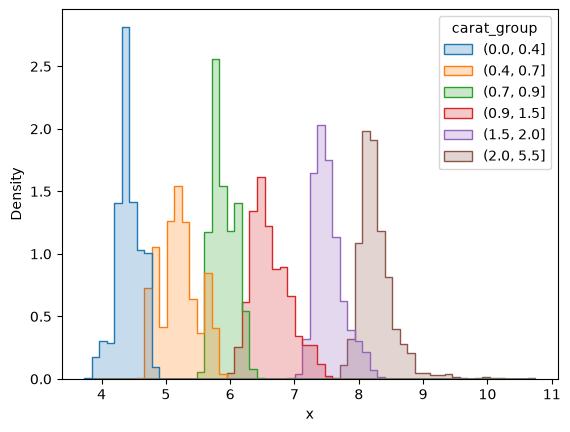

In [33]:
data['carat_group'] = pd.cut(
    data['carat'],
    bins=[0, 0.4, 0.7, 0.9, 1.5, 2, 5.5]
)

sns.histplot(
    data=data,
    x='x',
    hue='carat_group',
    bins=60,
    element='step',
    stat='density',
    common_norm=False
)

plt.show()

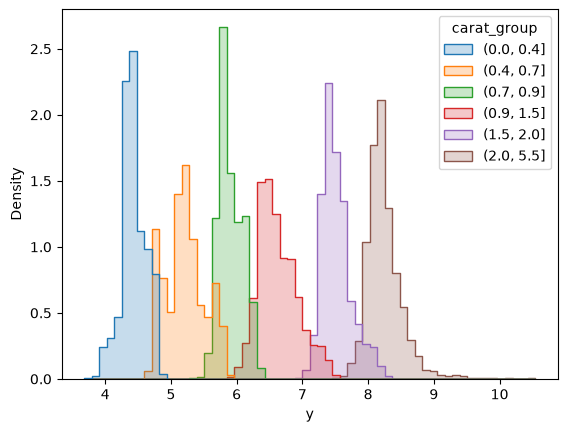

In [34]:
sns.histplot(
    data=data,
    x='y',
    hue='carat_group',
    bins=60,
    element='step',
    stat='density',
    common_norm=False
)

plt.show()

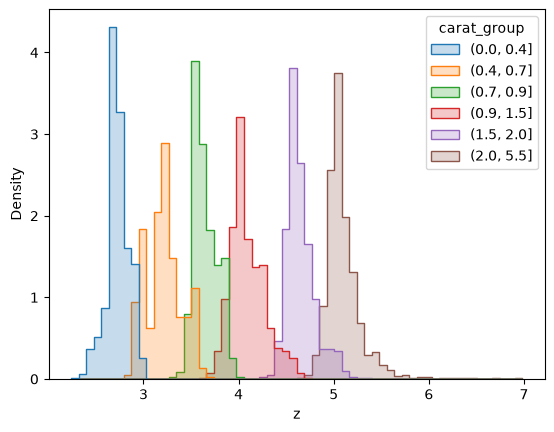

In [35]:
sns.histplot(
    data=data,
    x='z',
    hue='carat_group',
    bins=60,
    element='step',
    stat='density',
    common_norm=False
)

plt.show()

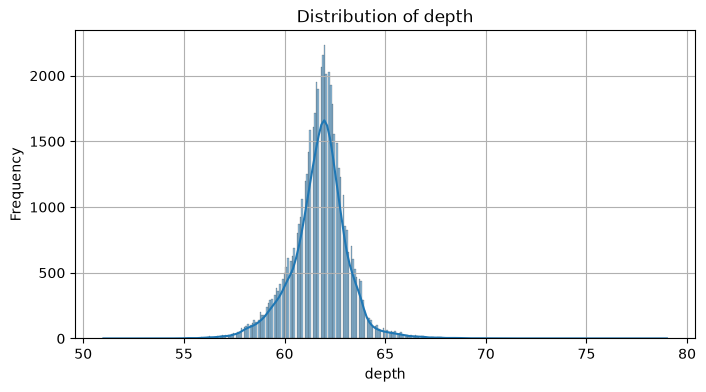

In [36]:
plot_hist_numeric(data, 'depth')

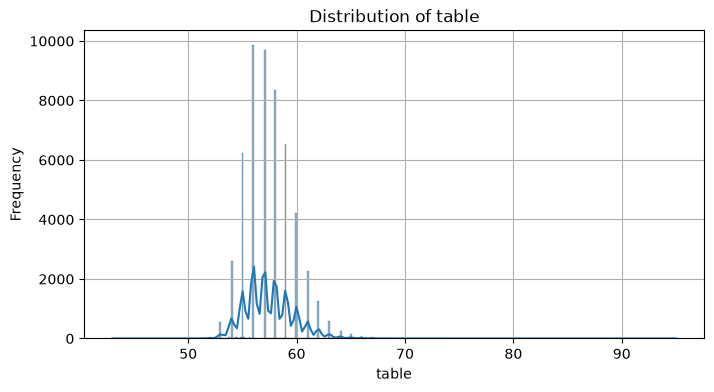

In [37]:
plot_hist_numeric(data, 'table')

## Корреляция

In [38]:
data.drop(['carat_group', 'depth_counted', 'depth_diff'], axis=1, inplace=True)

interval columns not set, guessing: ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']


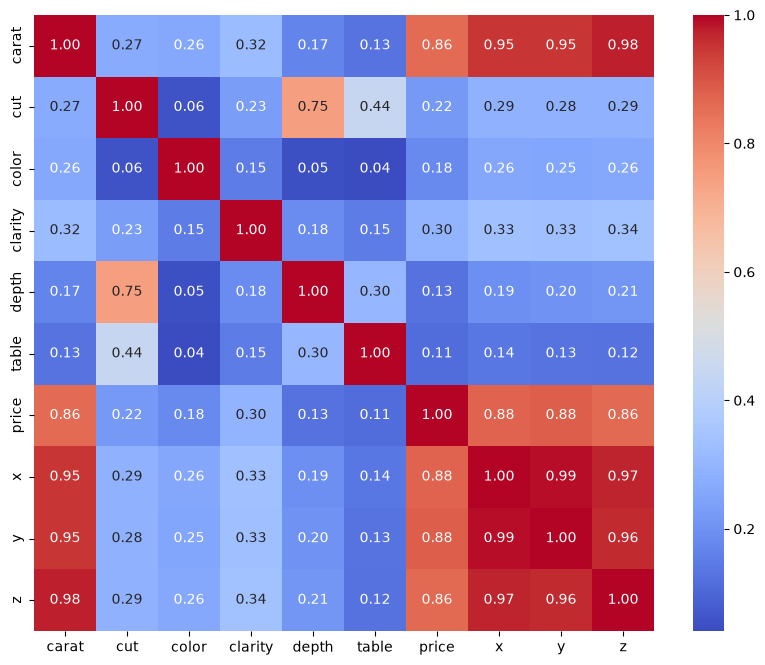

In [39]:
plot_phik(data)

Price - колонка, которую необходимо предсказать. Если обратить внимание на её строчку, то можно заметить, что она имеет высокую корреляцию с такими признаками как: carat, x, y, z. Есть корреляция и с другими признаками, но сильно меньше. Кроме того, гипотеза о зависимости признака carat и признаков x, y, z подтверждается и тут: их корреляция почти достигает 1.

## Два и более признака вместе

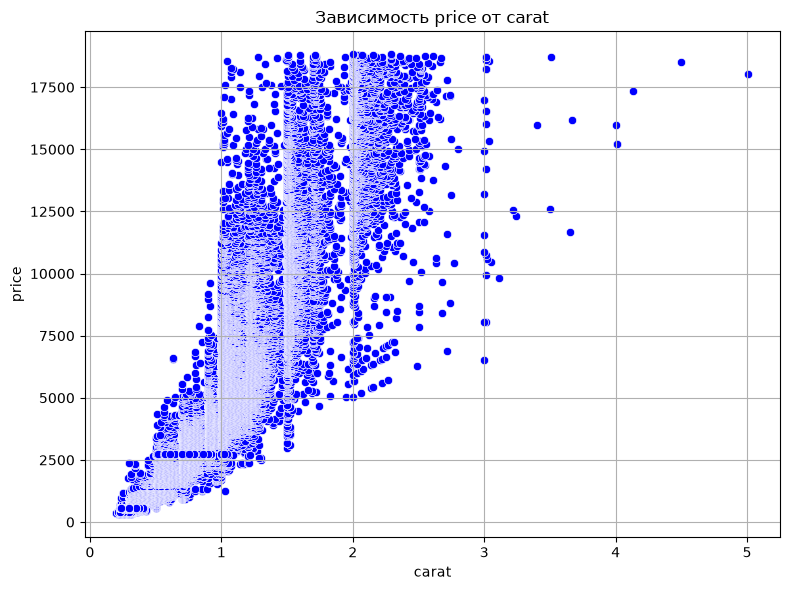

In [40]:
plot_numeric_relationship(data, 'carat', 'price')

На графике видно, что у цены нелинейная зависимость от карата: она скорее похожа или на квадратичную, или на степенную. Также заметна гетероскедастичность: у камней с меньшим значением веса (карат от 0 до 1) дисперсия цены значительно меньше (от 0 до 5000), чем у камней, у которых карат находится в диапазоне от 1 до 2 (их цена может варьироваться от 5000 до 17500). 

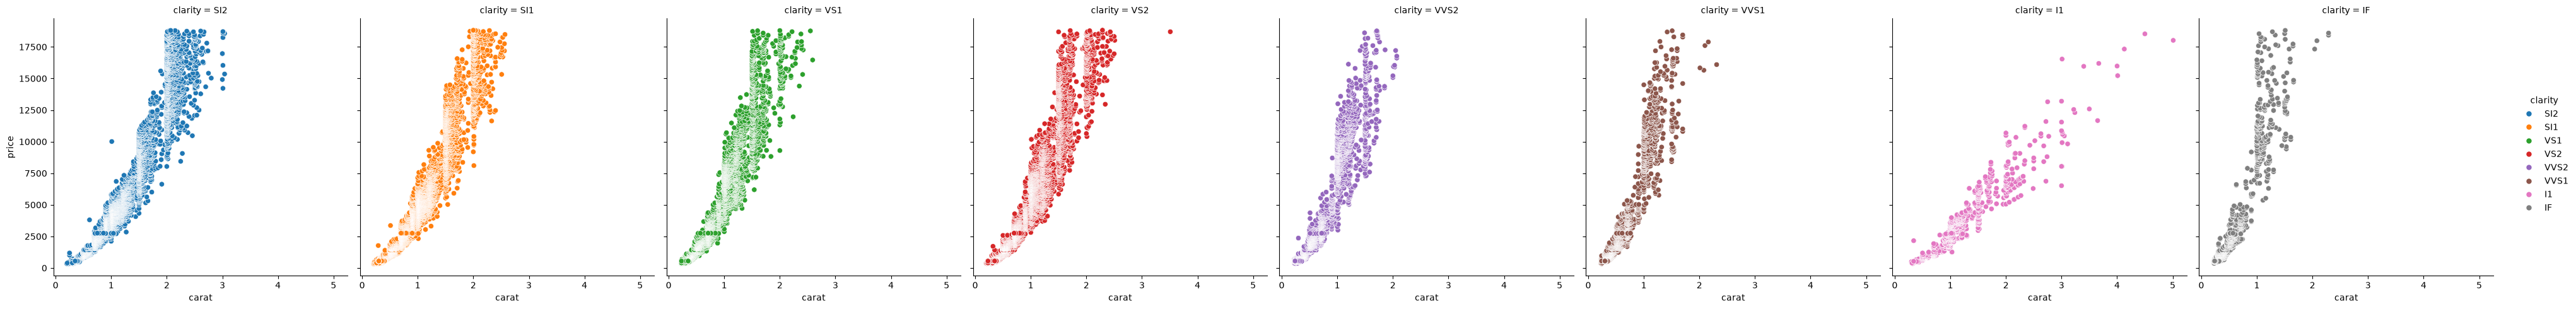

In [41]:
sns.relplot(
    data=data, 
    x='carat', 
    y='price', 
    col='clarity', 
    hue='clarity', 
    kind='scatter',
)

Здесь отрисовано несколько графиков: зависимость price от carat и разделенное по clarity. По графикам можно сделать вывод, что камни с clarity - 1l в основном самые дешёвые, а камни с clarity = If самые дорогие. Про остальные камни визуально сложно сказать в чем разница, но теперь точно ясно, что clarity - это признак имеющий порядок

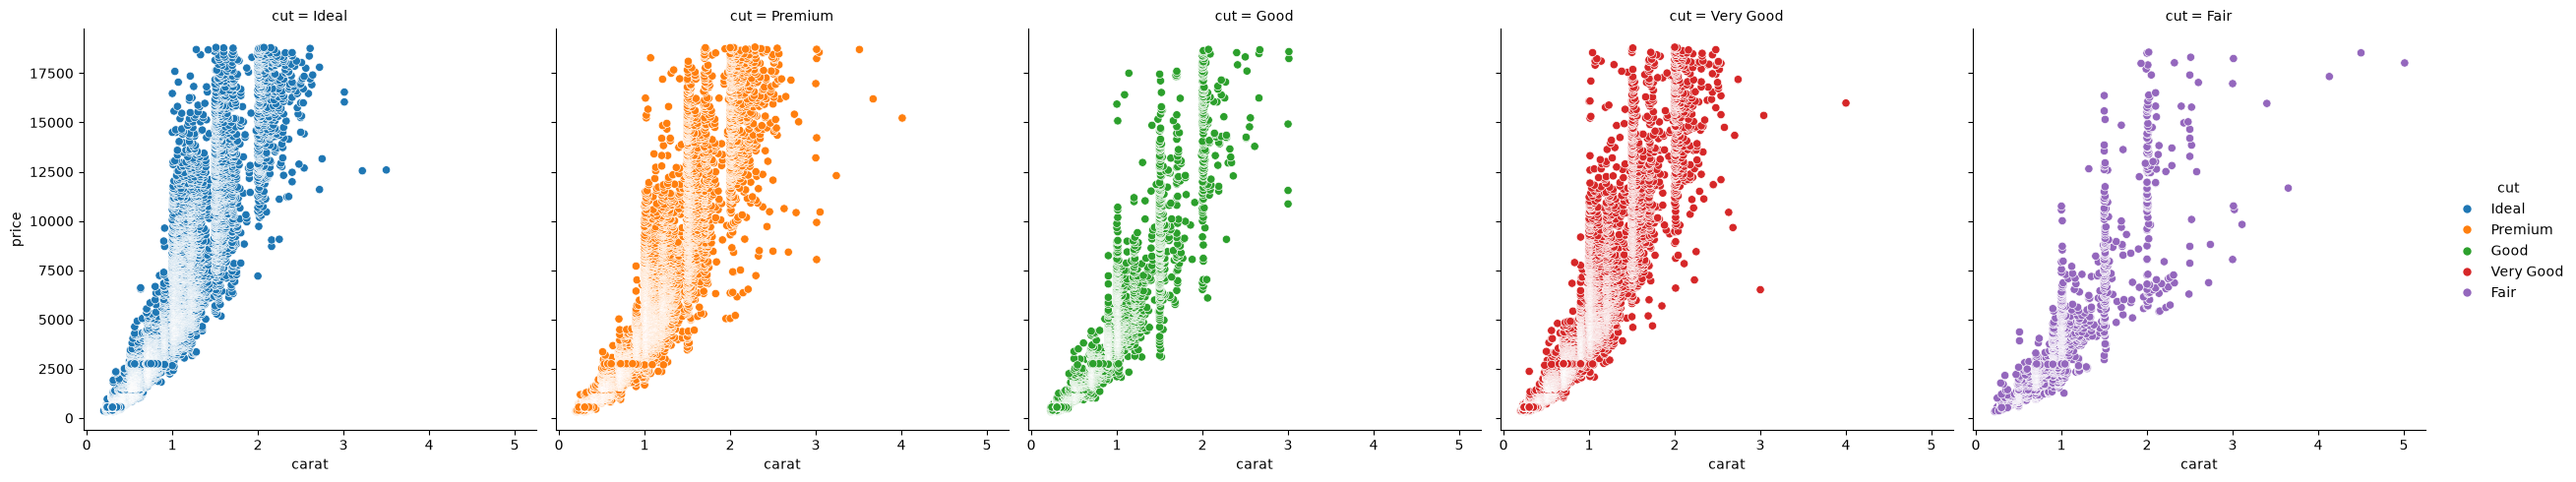

In [42]:
sns.relplot(
    data=data, 
    x='carat', 
    y='price', 
    col='cut', 
    hue='cut', 
    kind='scatter',
)

Похожий график по построению, но вместо clarity тут cut. По cut явно и четко не определить стоимость, ведь встречаются как дешёвые ideal, так и дорогие fair. 

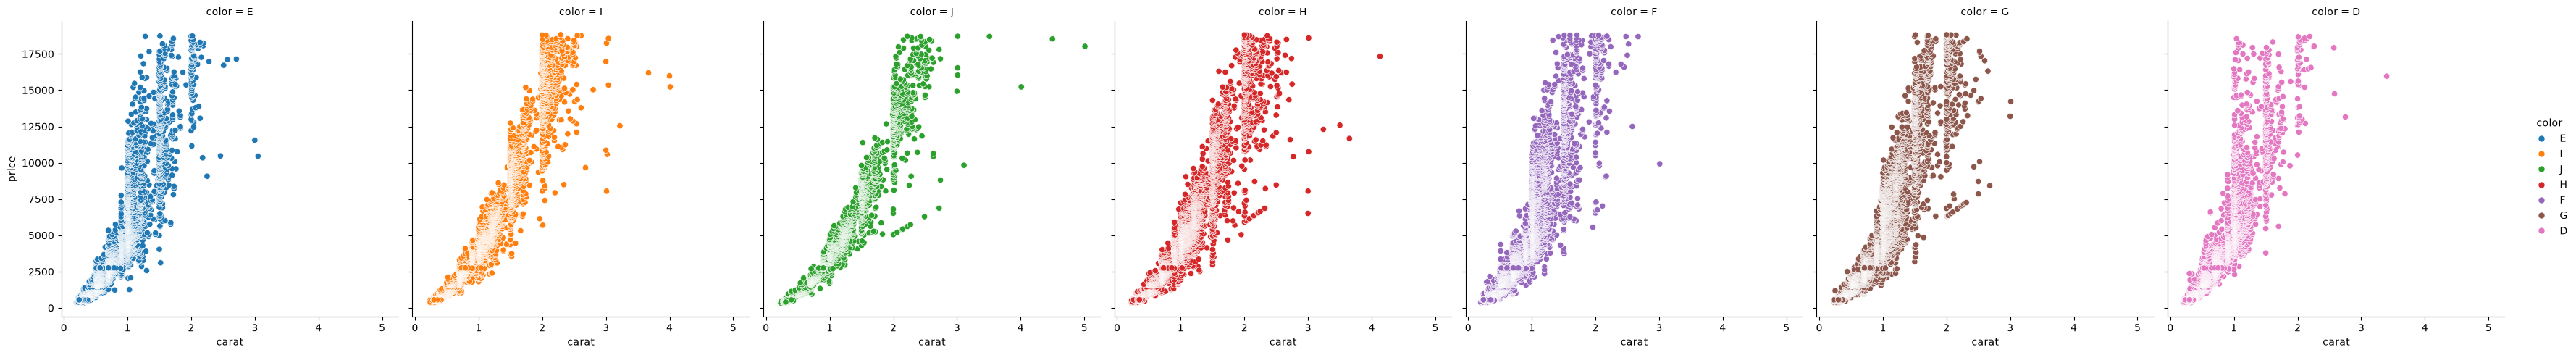

In [43]:
sns.relplot(
    data=data, 
    x='carat', 
    y='price', 
    col='color', 
    hue='color', 
    kind='scatter',
)

Color ... 

Далее рассмотрим влияние размеров на цену.

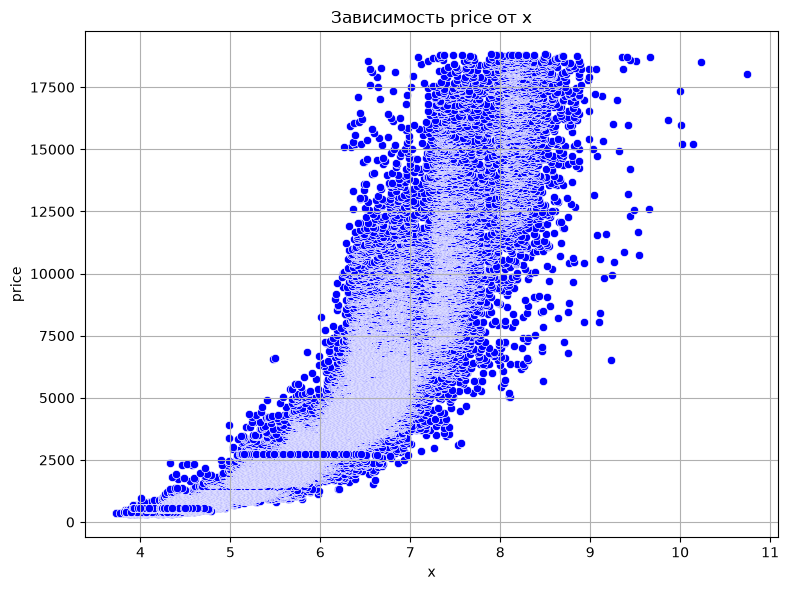

In [44]:
plot_numeric_relationship(data, 'x', 'price')

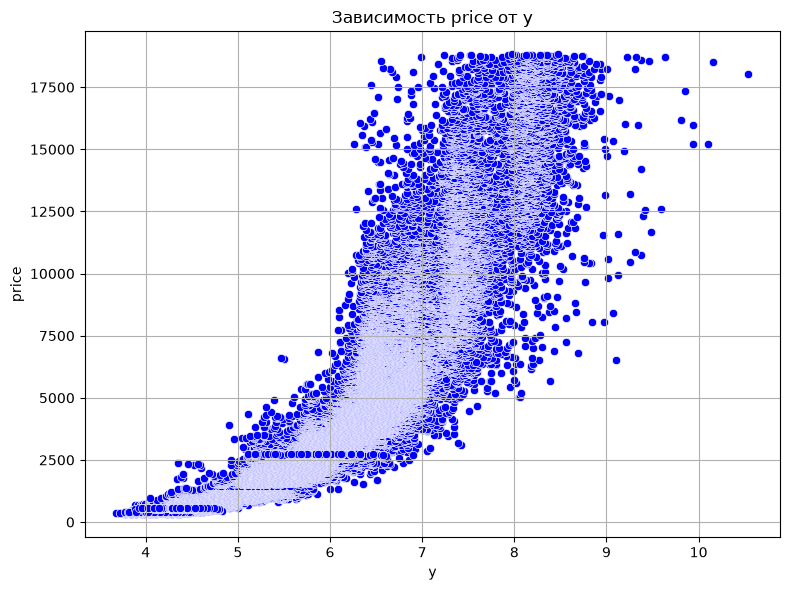

In [43]:
plot_numeric_relationship(data, 'y', 'price')

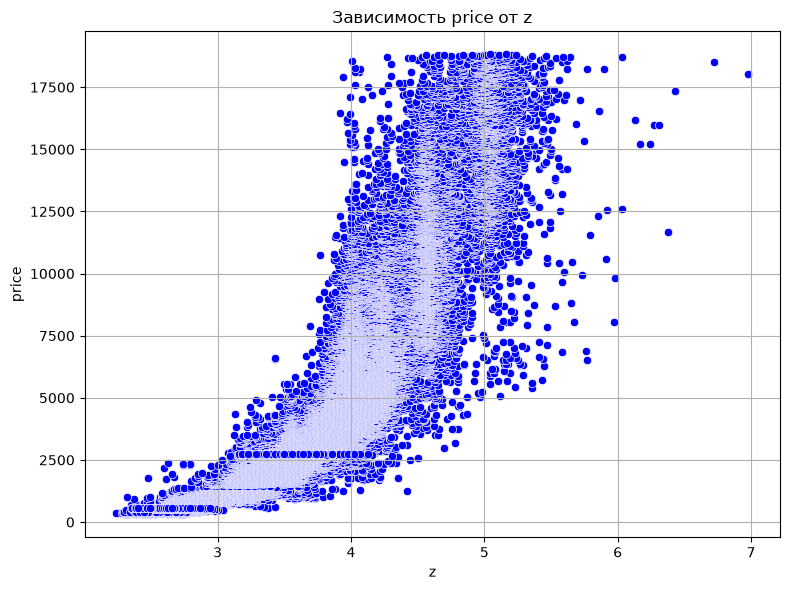

In [44]:
plot_numeric_relationship(data, 'z', 'price')

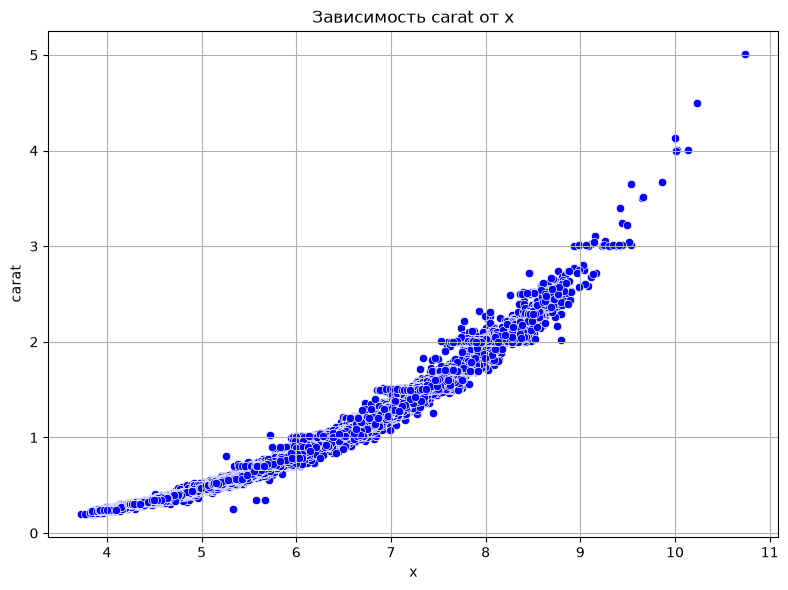

In [45]:
plot_numeric_relationship(data, 'x', 'carat')

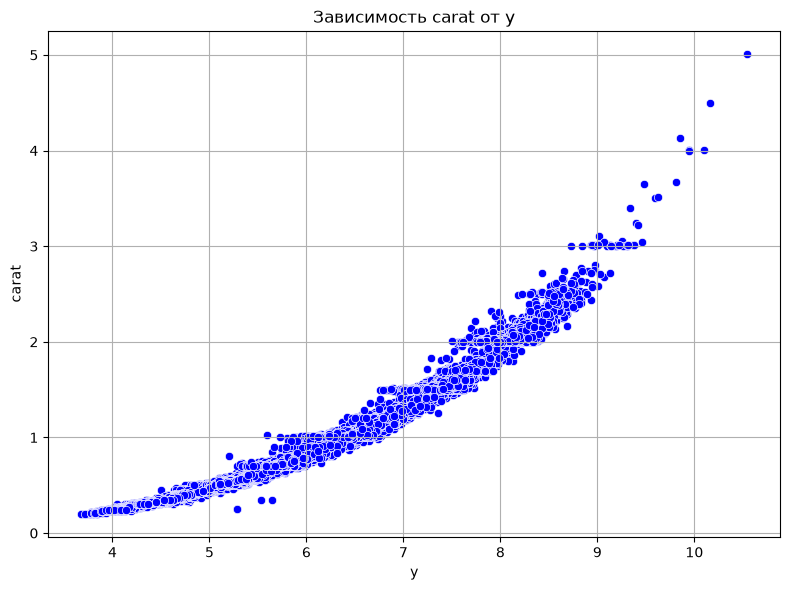

In [46]:
plot_numeric_relationship(data, 'y', 'carat')

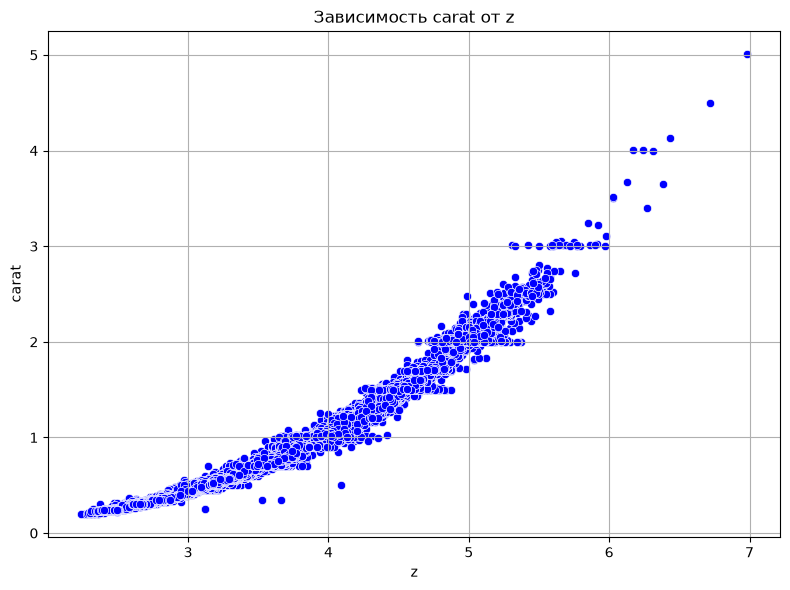

In [47]:
plot_numeric_relationship(data, 'z', 'carat')

Заивисимость carat от x, y, z чем-то напоминает степенную.

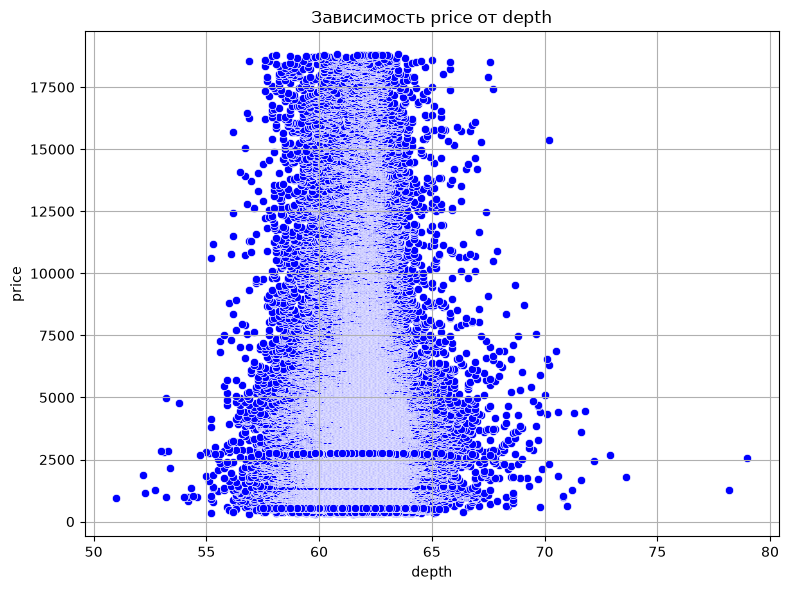

In [48]:
plot_numeric_relationship(data, 'depth', 'price')

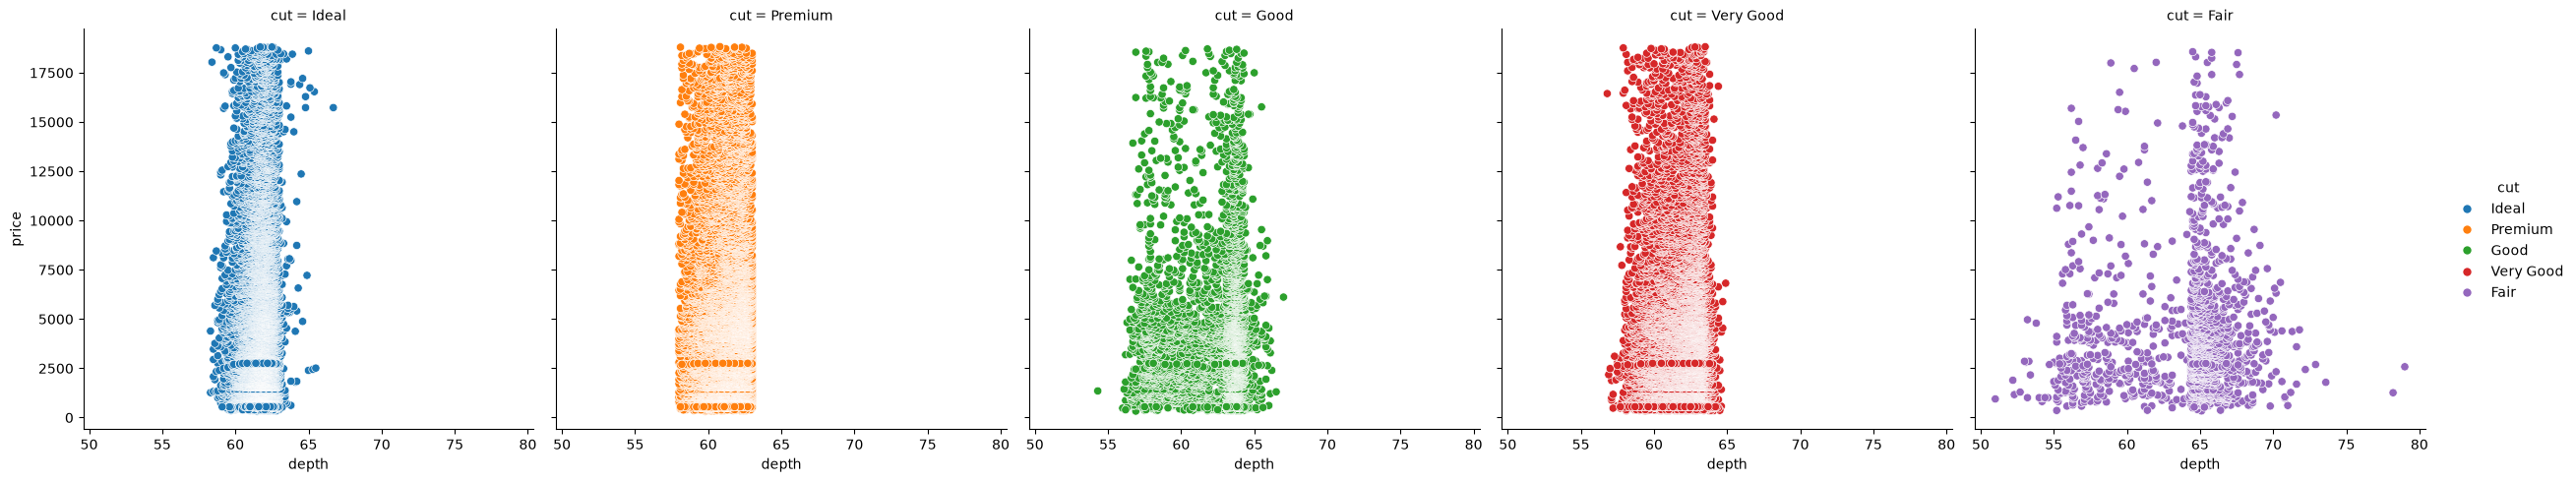

In [49]:
sns.relplot(
    data=data, 
    x='depth', 
    y='price', 
    col='cut', 
    hue='cut', 
    kind='scatter',
)

У премиальной и идеальной огранки диапазон глубины более узкий, чем у остальных типов огранки. Особенно выделяется премиальный тип с чёткими ограничениями по глубине. Выбросы по глубине зачастую принадлежат к типу огранки Fair.

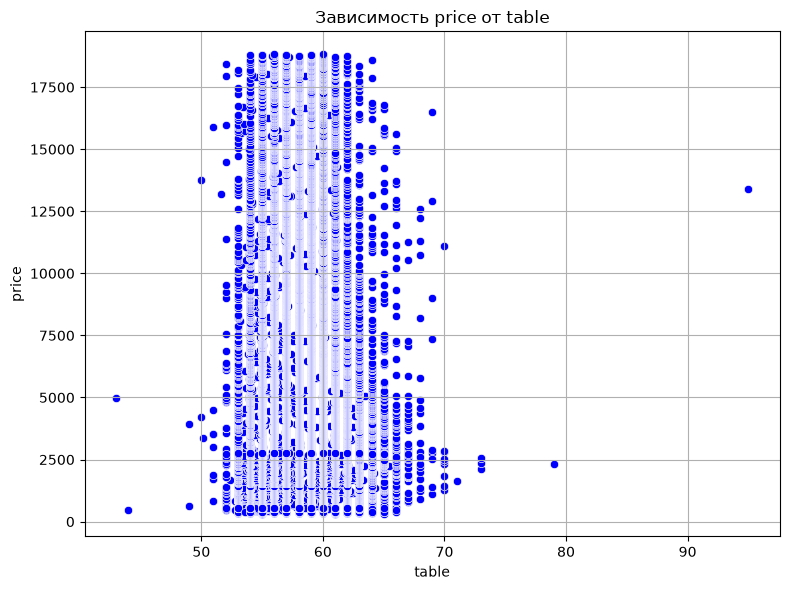

In [50]:
plot_numeric_relationship(data, 'table', 'price')

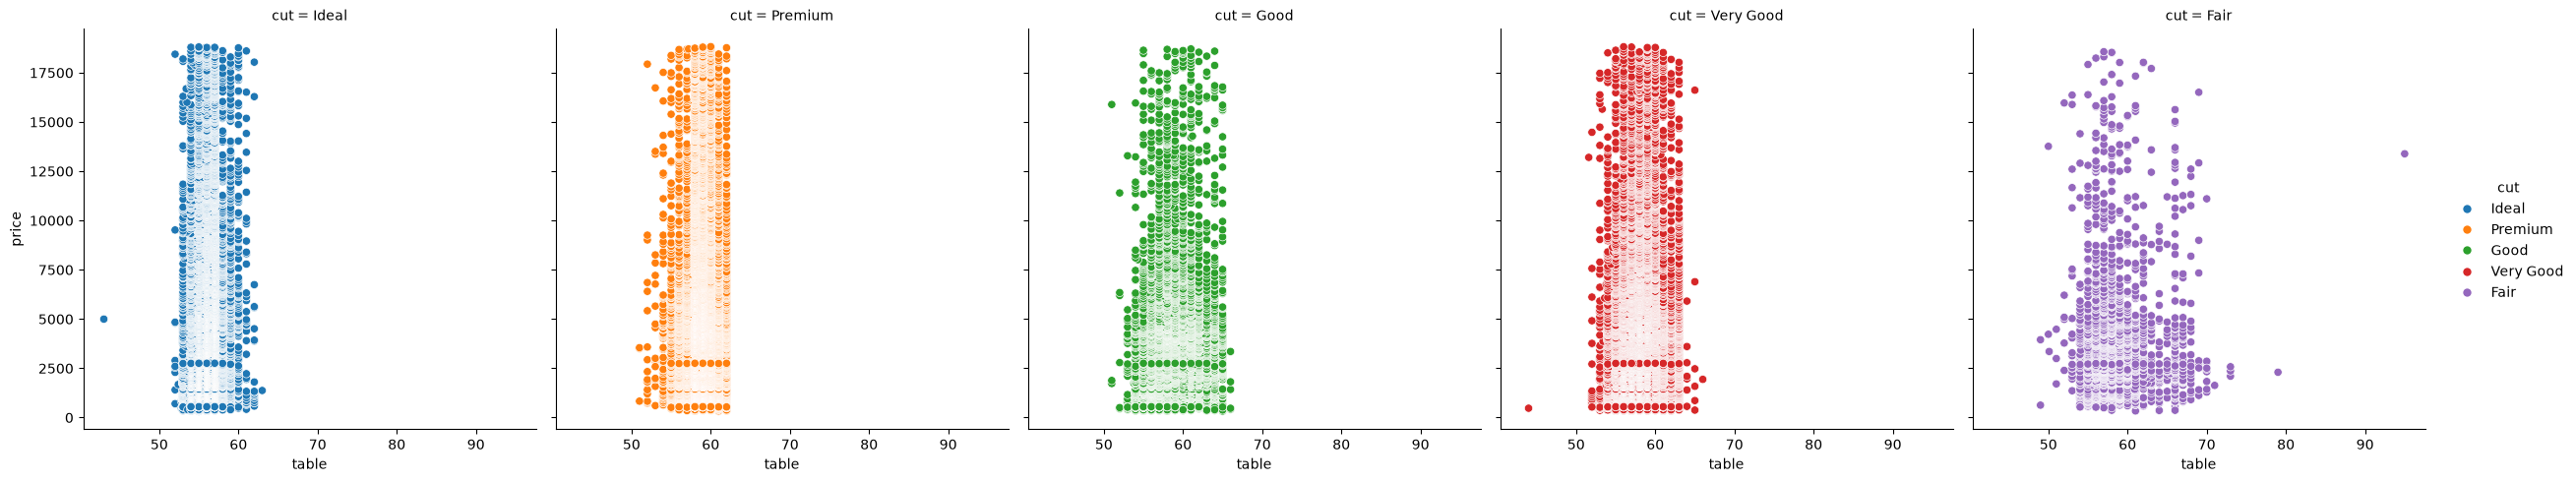

In [51]:
sns.relplot(
    data=data, 
    x='table', 
    y='price', 
    col='cut', 
    hue='cut', 
    kind='scatter',
)

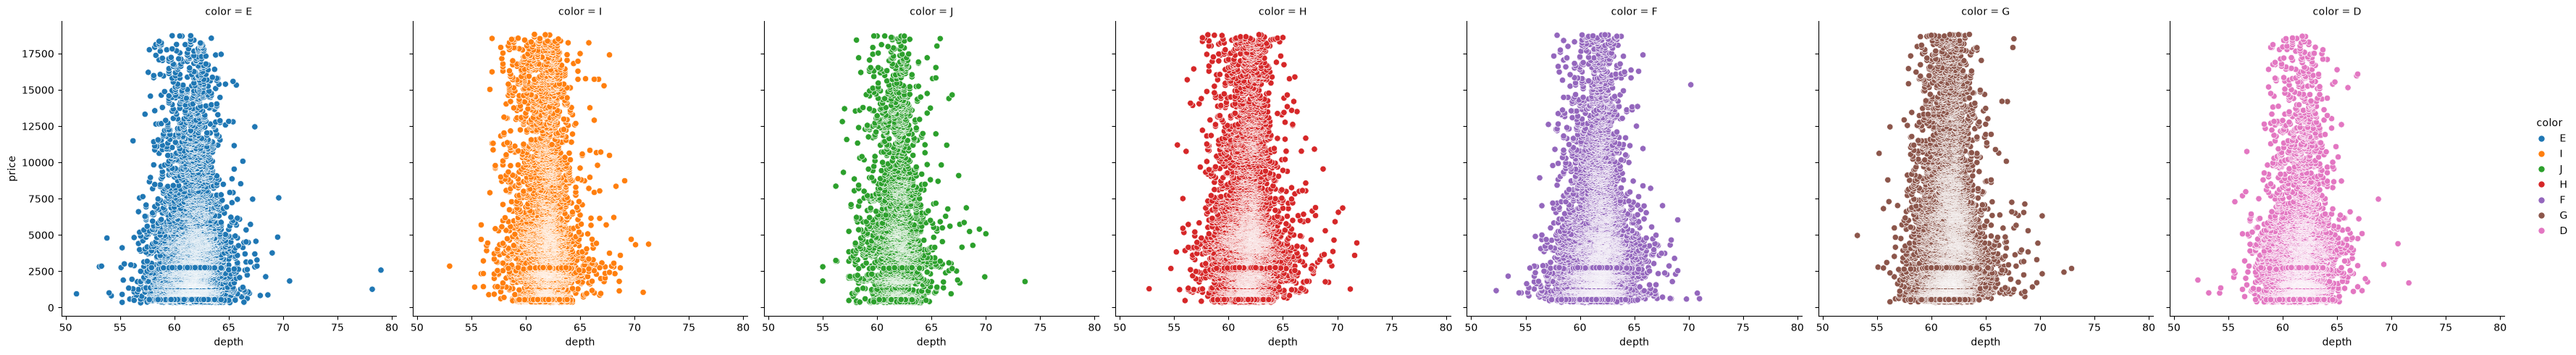

In [52]:
sns.relplot(
    data=data, 
    x='depth', 
    y='price', 
    col='color', 
    hue='color', 
    kind='scatter',
)

# Построение Baselines

In [54]:
data.head(3)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31


In [55]:
X, y = data.drop(columns=['price']), data['price']

In [56]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

In [57]:
X_train_processed = X_train.copy()
ordered_categories = {
    'cut': ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal'],
    'color': ['J', 'I', 'H', 'G', 'F', 'E', 'D'],
    'clarity': ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']
}
numeric_features = ['carat', 'depth', 'table', 'x', 'y', 'z']

In [58]:
preprocessor = Pipeline(steps=[
    ('column_transformer', ColumnTransformer(
        transformers=[
            ('ordinal_encoder',
             OrdinalEncoder(categories=[
                 ordered_categories['cut'],
                 ordered_categories['color'],
                 ordered_categories['clarity']
             ]),
             list(ordered_categories.keys())),

            ('num', 'passthrough', numeric_features)
        ],
        verbose_feature_names_out=False
    ))
])

preprocessor.set_output(transform="pandas")

,steps,"[('column_transformer', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal_encoder', ...), ('num', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_we

In [59]:
X_train_preprocessed = preprocessor.fit_transform(X_train)

X_train_preprocessed = pd.DataFrame(
    X_train_preprocessed,
    columns=preprocessor.get_feature_names_out(),
    index=X_train.index
)

In [60]:
print(X_train_preprocessed.shape)
X_train_preprocessed.head(3)

(42956, 9)


,cut,color,clarity,carat,depth,table,x,y,z
40699,4.0,5.0,5.0,0.40,61.7,55.0,4.74,4.76,2.93
27100,2.0,4.0,1.0,2.01,60.8,57.0,8.09,8.15,4.94
28144,4.0,3.0,5.0,0.30,62.3,57.0,4.29,4.32,2.68


In [61]:
X_test_preprocessed = preprocessor.transform(X_test)
X_test_preprocessed

,cut,color,clarity,carat,depth,table,x,y,z
8454,4.0,1.0,2.0,1.01,62.5,56.0,6.40,6.44,4.01
1184,4.0,3.0,6.0,0.71,61.7,57.0,5.75,5.70,3.53
30187,0.0,3.0,3.0,0.40,64.6,55.0,4.62,4.64,2.99
29070,4.0,6.0,3.0,0.34,61.6,55.0,4.48,4.54,2.78
1225,2.0,4.0,5.0,0.70,62.6,59.0,5.60,5.64,3.52
...,...,...,...,...,...,...,...,...,...
27221,2.0,1.0,3.0,2.01,62.4,58.0,8.06,7.99,5.01
1072,3.0,1.0,3.0,0.31,62.3,60.0,4.32,4.31,2.69
46055,3.0,5.0,3.0,0.51,61.4,56.0,5.18,5.15,3.17
13931,1.0,2.0,4.0,1.00,60.2,63.0,6.43,6.47,3.88


# Baselines

In [63]:
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train_preprocessed, y_train)
y_pred = dummy.predict(X_test_preprocessed)
dummy_metrics = evaluate_regression(y_test, y_pred)
dummy_metrics

{'MAE': 3002.778037774287,
 'RMSE': np.float64(3950.55951193633),
 'R²': -0.00015347550986266612}

In [64]:
linear_reg = LinearRegression()
linear_reg.fit(X_train_preprocessed, y_train)
y_pred = linear_reg.predict(X_test_preprocessed)
linear_reg_metrics = evaluate_regression(y_test, y_pred)
linear_reg_metrics

{'MAE': 779.480122527984,
 'RMSE': np.float64(1186.8006987695653),
 'R²': 0.9097379862942389}

/home/bibeda/DSpractice/Classic_ML_reg/plots.py:305: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature',


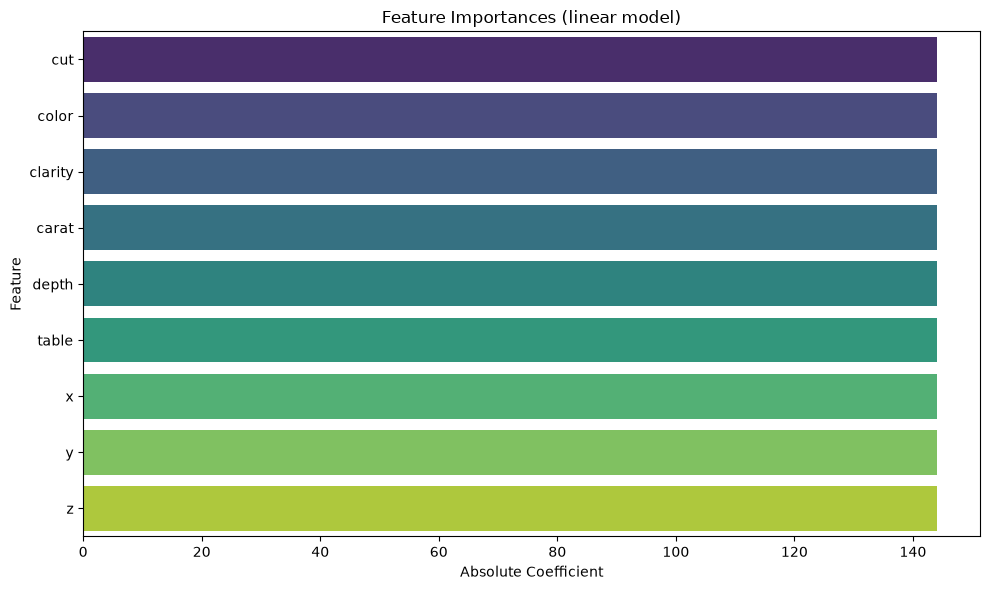

,Feature,Importance
0,cut,144.109054
1,color,144.109054
2,clarity,144.109054
3,carat,144.109054
4,depth,144.109054
5,table,144.109054
6,x,144.109054
7,y,144.109054
8,z,144.109054


In [65]:
plot_feature_importance(linear_reg, X_train_preprocessed.columns)

In [66]:
lgbm = LGBMRegressor(random_state=SEED)
lgbm.fit(X_train_preprocessed, y_train)
y_pred = lgbm.predict(X_test_preprocessed)
lgbm_metrics = evaluate_regression(y_test, y_pred)
lgbm_metrics

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002196 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1277
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 9
[LightGBM] [Info] Start training from score 3938.566859


{'MAE': 275.821861954689,
 'RMSE': np.float64(521.6152432110061),
 'R²': 0.98256387474465}

/home/bibeda/DSpractice/Classic_ML_reg/plots.py:305: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature',


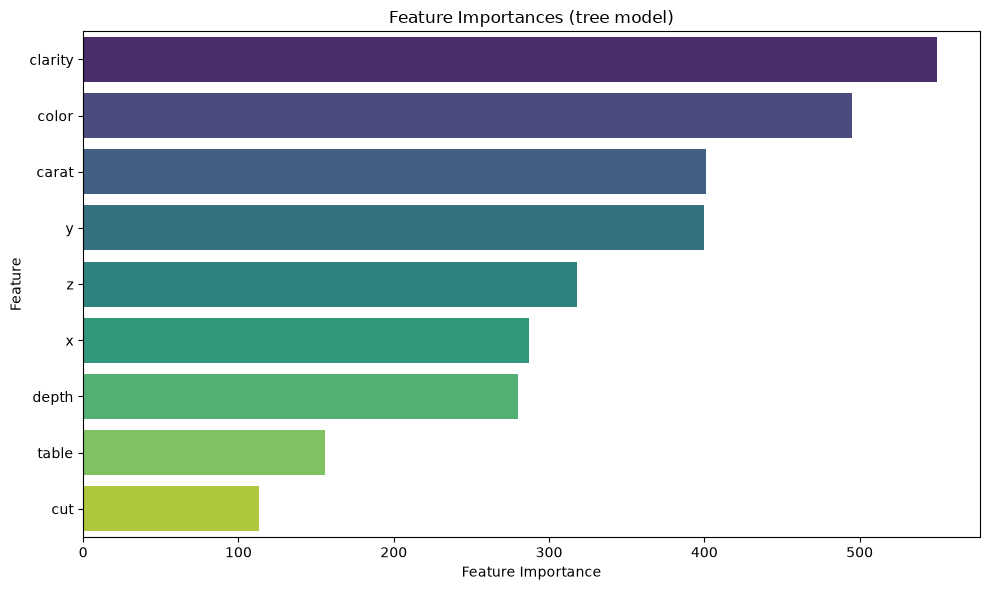

,Feature,Importance
2,clarity,550
1,color,495
3,carat,401
7,y,400
8,z,318
6,x,287
4,depth,280
5,table,156
0,cut,113


In [ ]:
plot_feature_importance(lgbm, X_train_preprocessed.columns)

In [67]:
random_forest = RandomForestRegressor(random_state=SEED)
random_forest.fit(X_train_preprocessed, y_train)
y_pred = random_forest.predict(X_test_preprocessed)
random_forest_metrics = evaluate_regression(y_test, y_pred)
random_forest_metrics

{'MAE': 264.85628712547503,
 'RMSE': np.float64(533.0404389024768),
 'R²': 0.9817916854511886}

/home/bibeda/DSpractice/Classic_ML_reg/plots.py:305: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature',


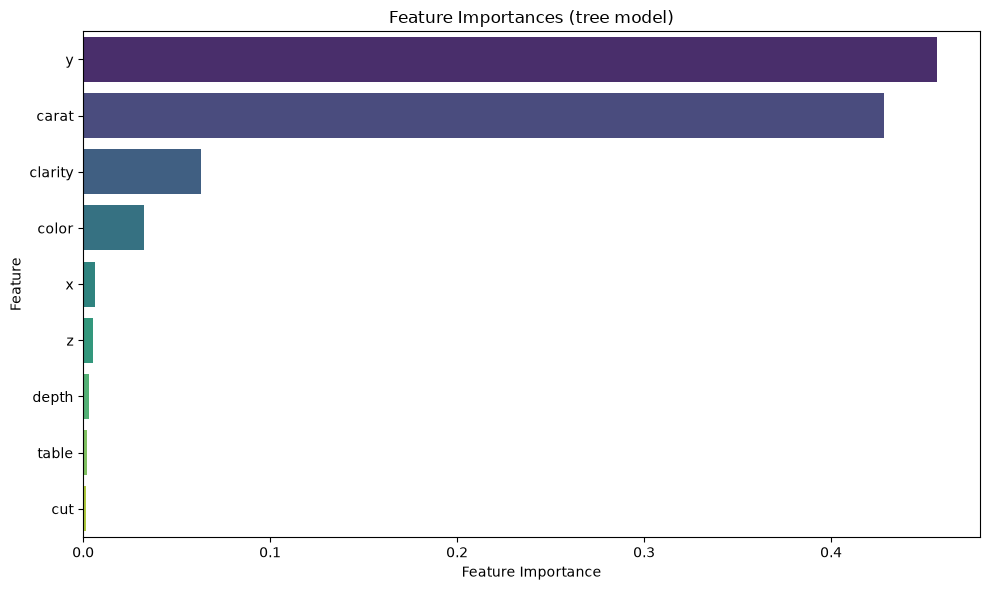

,Feature,Importance
7,y,0.456800
3,carat,0.428450
2,clarity,0.063095
1,color,0.032432
6,x,0.006557
8,z,0.005474
4,depth,0.003197
5,table,0.002267
0,cut,0.001728


In [68]:
plot_feature_importance(random_forest, X_train_preprocessed.columns)

In [69]:
decision_tree = DecisionTreeRegressor(random_state=SEED)
decision_tree.fit(X_train_preprocessed, y_train)
y_pred = decision_tree.predict(X_test_preprocessed)
decision_tree_metrics = evaluate_regression(y_test, y_pred)
decision_tree_metrics

{'MAE': 353.34183815997767,
 'RMSE': np.float64(718.3113095932182),
 'R²': 0.9669345193478017}

/home/bibeda/DSpractice/Classic_ML_reg/plots.py:305: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature',


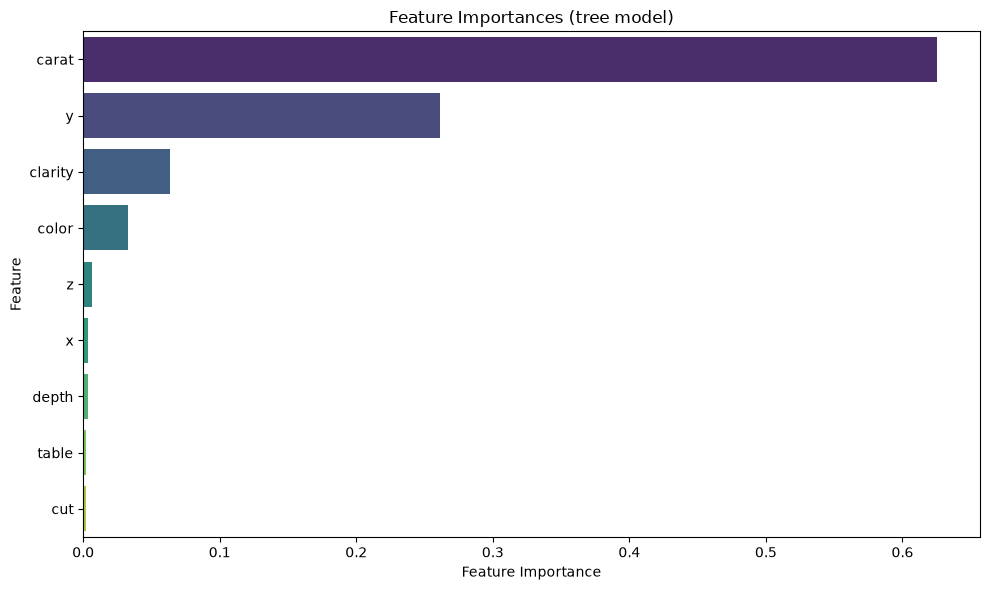

,Feature,Importance
3,carat,0.625515
7,y,0.261413
2,clarity,0.063439
1,color,0.032479
8,z,0.006123
6,x,0.003588
4,depth,0.003178
5,table,0.002410
0,cut,0.001856


In [70]:
plot_feature_importance(decision_tree, X_train_preprocessed.columns)

In [71]:
final_metrics = {
    'dummy_regressor': dummy_metrics,
    'linear_regression': linear_reg_metrics,
    'default_decision_tree': decision_tree_metrics,
    'random_forest': random_forest_metrics,
    'lgbm': lgbm_metrics
}

result = pd.DataFrame(final_metrics.values(), index=final_metrics.keys())

<Axes: >

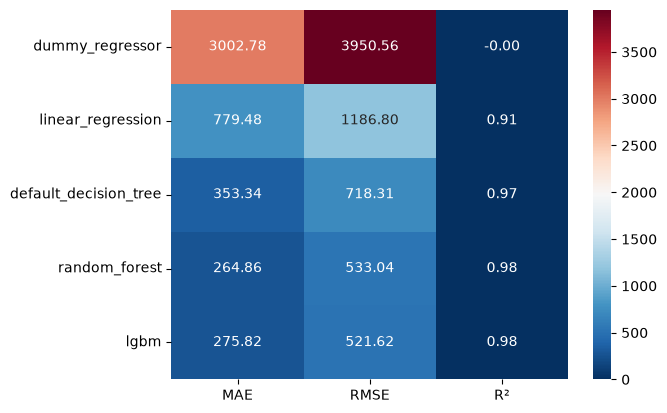

In [72]:
sns.heatmap(result, cmap='RdBu_r', annot=True, fmt=".2f")